In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3 as sql


In [2]:
dir(sql)


['Binary',
 'Blob',
 'Connection',
 'Cursor',
 'DataError',
 'DatabaseError',
 'Date',
 'DateFromTicks',
 'Error',
 'IntegrityError',
 'InterfaceError',
 'InternalError',
 'LEGACY_TRANSACTION_CONTROL',
 'NotSupportedError',
 'OperationalError',
 'PARSE_COLNAMES',
 'PARSE_DECLTYPES',
 'PrepareProtocol',
 'ProgrammingError',
 'Row',
 'SQLITE_ABORT',
 'SQLITE_ABORT_ROLLBACK',
 'SQLITE_ALTER_TABLE',
 'SQLITE_ANALYZE',
 'SQLITE_ATTACH',
 'SQLITE_AUTH',
 'SQLITE_AUTH_USER',
 'SQLITE_BUSY',
 'SQLITE_BUSY_RECOVERY',
 'SQLITE_BUSY_SNAPSHOT',
 'SQLITE_BUSY_TIMEOUT',
 'SQLITE_CANTOPEN',
 'SQLITE_CANTOPEN_CONVPATH',
 'SQLITE_CANTOPEN_DIRTYWAL',
 'SQLITE_CANTOPEN_FULLPATH',
 'SQLITE_CANTOPEN_ISDIR',
 'SQLITE_CANTOPEN_NOTEMPDIR',
 'SQLITE_CANTOPEN_SYMLINK',
 'SQLITE_CONSTRAINT',
 'SQLITE_CONSTRAINT_CHECK',
 'SQLITE_CONSTRAINT_COMMITHOOK',
 'SQLITE_CONSTRAINT_FOREIGNKEY',
 'SQLITE_CONSTRAINT_FUNCTION',
 'SQLITE_CONSTRAINT_NOTNULL',
 'SQLITE_CONSTRAINT_PINNED',
 'SQLITE_CONSTRAINT_PRIMARYKEY',
 'SQLIT

In [3]:
conn = sql.connect('chinook1')
conn

In [4]:
'select * from sqllite_master'

'select * from sqllite_master'

In [5]:
pd.read_sql_query('select * from sqlite_master',conn)

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


In [6]:
pd.read_sql_query("SELECT * FROM artist", conn)

,artist_id,name
0,1,AC/DC
1,2,Accept
2,3,Aerosmith
3,4,Alanis Morissette
4,5,Alice In Chains
...,...,...
270,271,"Mela Tenenbaum, Pro Musica Prague & Richard Kapp"
271,272,Emerson String Quartet
272,273,"C. Monteverdi, Nigel Rogers - Chiaroscuro; Lon..."
273,274,Nash Ensemble


In [7]:
pd.read_sql_query("SELECT * FROM album", conn)

,album_id,title,artist_id
0,1,For Those About To Rock We Salute You,1
1,2,Balls to the Wall,2
2,3,Restless and Wild,2
3,4,Let There Be Rock,1
4,5,Big Ones,3
...,...,...,...
342,343,Respighi:Pines of Rome,226
343,344,Schubert: The Late String Quartets & String Qu...,272
344,345,Monteverdi: L'Orfeo,273
345,346,Mozart: Chamber Music,274


In [8]:
pd.read_sql_query("SELECT * FROM track", conn)

,track_id,name,album_id,media_type_id,genre_id,composer,milliseconds,bytes,unit_price
0,1,For Those About To Rock (We Salute You),1,1,1,"Angus Young, Malcolm Young, Brian Johnson",343719,11170334,0.99
1,2,Balls to the Wall,2,2,1,None,342562,5510424,0.99
2,3,Fast As a Shark,3,2,1,"F. Baltes, S. Kaufman, U. Dirkscneider & W. Ho...",230619,3990994,0.99
3,4,Restless and Wild,3,2,1,"F. Baltes, R.A. Smith-Diesel, S. Kaufman, U. D...",252051,4331779,0.99
4,5,Princess of the Dawn,3,2,1,Deaffy & R.A. Smith-Diesel,375418,6290521,0.99
...,...,...,...,...,...,...,...,...,...
3498,3499,Pini Di Roma (Pinien Von Rom) \ I Pini Della V...,343,2,24,None,286741,4718950,0.99
3499,3500,"String Quartet No. 12 in C Minor, D. 703 ""Quar...",344,2,24,Franz Schubert,139200,2283131,0.99
3500,3501,"L'orfeo, Act 3, Sinfonia (Orchestra)",345,2,24,Claudio Monteverdi,66639,1189062,0.99
3501,3502,"Quintet for Horn, Violin, 2 Violas, and Cello ...",346,2,24,Wolfgang Amadeus Mozart,221331,3665114,0.99


In [9]:
pd.read_sql_query("SELECT * FROM genre", conn)

,genre_id,name
0,1,Rock
1,2,Jazz
2,3,Metal
3,4,Alternative & Punk
4,5,Rock And Roll
5,6,Blues
6,7,Latin
7,8,Reggae
8,9,Pop
9,10,Soundtrack


In [10]:
q1 = """
SELECT g.name AS genre,
       COUNT(t.track_id) AS track_count
FROM genre g
JOIN track t
ON g.genre_id = t.genre_id
GROUP BY g.genre_id, g.name
ORDER BY track_count DESC
LIMIT 10
"""

df1 = pd.read_sql_query(q1, conn)
df1

,genre,track_count
0,Rock,1297
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61


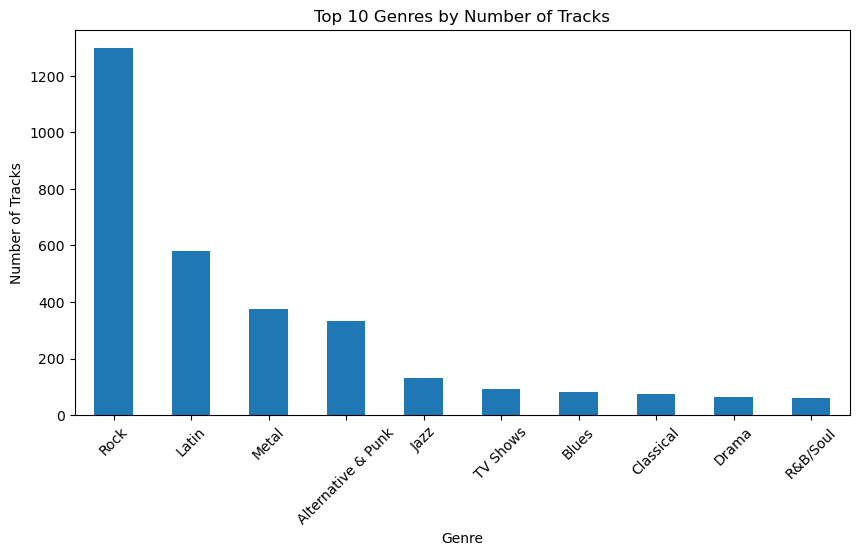

In [11]:
df1.plot(
    x="genre",
    y="track_count",
    kind="bar",
    figsize=(10,5),
    legend=False
)

plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.title("Top 10 Genres by Number of Tracks")
plt.xticks(rotation=45)
plt.show()

In [12]:
q2 = """
SELECT a.title AS album,
       COUNT(t.track_id) AS track_count
FROM album a
JOIN track t
ON a.album_id = t.album_id
GROUP BY a.album_id, a.title
ORDER BY track_count DESC
LIMIT 10
"""

df2 = pd.read_sql_query(q2, conn)
df2

,album,track_count
0,Greatest Hits,57
1,Minha Historia,34
2,Unplugged,30
3,"Lost, Season 3",26
4,"Lost, Season 1",25
5,"The Office, Season 3",25
6,My Way: The Best Of Frank Sinatra [Disc 1],24
7,"Lost, Season 2",24
8,"Battlestar Galactica (Classic), Season 1",24
9,Afrociberdelia,23


In [13]:
q3 = """
SELECT c.customer_id,
       c.first_name || ' ' || c.last_name AS customer,
       SUM(i.total) AS total_spent
FROM customer c
JOIN invoice i
ON c.customer_id = i.customer_id
GROUP BY c.customer_id, c.first_name, c.last_name
ORDER BY total_spent DESC
LIMIT 10
"""

df3 = pd.read_sql_query(q3, conn)
df3

,customer_id,customer,total_spent
0,5,František Wichterlová,144.54
1,6,Helena Holý,128.70
2,46,Hugh O'Reilly,114.84
3,58,Manoj Pareek,111.87
4,1,Luís Gonçalves,108.90
5,13,Fernanda Ramos,106.92
6,34,João Fernandes,102.96
7,3,François Tremblay,99.99
8,42,Wyatt Girard,99.99
9,17,Jack Smith,98.01


In [14]:
q4 = """
SELECT ar.name AS artist,
       SUM(il.unit_price * il.quantity) AS revenue
FROM artist ar
JOIN album al
ON ar.artist_id = al.artist_id
JOIN track t
ON al.album_id = t.album_id
JOIN invoice_line il
ON t.track_id = il.track_id
GROUP BY ar.artist_id, ar.name
ORDER BY revenue DESC
LIMIT 5
"""

df4 = pd.read_sql_query(q4, conn)
df4

,artist,revenue
0,Queen,190.08
1,Jimi Hendrix,185.13
2,Nirvana,128.70
3,Red Hot Chili Peppers,128.70
4,Pearl Jam,127.71


In [15]:
q5 = """
SELECT billing_country AS country,
       AVG(total) AS avg_revenue_per_invoice
FROM invoice
GROUP BY billing_country
ORDER BY avg_revenue_per_invoice DESC
"""

df5 = pd.read_sql_query(q5, conn)
df5

,country,avg_revenue_per_invoice
0,Czech Republic,9.108000
1,Spain,8.910000
2,Ireland,8.833846
3,United Kingdom,8.768571
4,India,8.721429
5,Belgium,8.627143
6,Germany,8.161463
7,Australia,8.118000
8,Norway,8.030000
9,USA,7.942672


In [16]:
q6 = """
SELECT m.name AS media_type,
       COUNT(t.track_id) AS track_count
FROM media_type m
JOIN track t
ON m.media_type_id = t.media_type_id
GROUP BY m.media_type_id, m.name
ORDER BY track_count DESC
"""

df6 = pd.read_sql_query(q6, conn)
df6

,media_type,track_count
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


In [17]:
q7 = """
SELECT ar.name AS artist,
       COUNT(DISTINCT t.genre_id) AS genre_count
FROM artist ar
JOIN album al
ON ar.artist_id = al.artist_id
JOIN track t
ON al.album_id = t.album_id
GROUP BY ar.artist_id, ar.name
HAVING COUNT(DISTINCT t.genre_id) > 1
ORDER BY genre_count DESC
"""

df7 = pd.read_sql_query(q7, conn)
df7

,artist,genre_count
0,Iron Maiden,4
1,Audioslave,3
2,Various Artists,3
3,Gilberto Gil,3
4,Jamiroquai,3
5,Lenny Kravitz,3
6,Battlestar Galactica,3
7,Antônio Carlos Jobim,2
8,Eric Clapton,2
9,Faith No More,2


In [18]:
q8 = """
SELECT name,
       milliseconds,
       milliseconds / 60000.0 AS duration_minutes
FROM track
ORDER BY milliseconds DESC
LIMIT 10
"""

df8 = pd.read_sql_query(q8, conn)
df8

,name,milliseconds,duration_minutes
0,Occupation / Precipice,5286953,88.115883
1,Through a Looking Glass,5088838,84.813967
2,"Greetings from Earth, Pt. 1",2960293,49.338217
3,The Man With Nine Lives,2956998,49.283300
4,"Battlestar Galactica, Pt. 2",2956081,49.268017
5,"Battlestar Galactica, Pt. 1",2952702,49.211700
6,Murder On the Rising Star,2935894,48.931567
7,"Battlestar Galactica, Pt. 3",2927802,48.796700
8,Take the Celestra,2927677,48.794617
9,Fire In Space,2926593,48.776550


In [19]:
q9 = """
WITH artist_revenue AS (
    SELECT ar.name AS artist,
           SUM(il.unit_price * il.quantity) AS revenue
    FROM artist ar
    JOIN album al
    ON ar.artist_id = al.artist_id
    JOIN track t
    ON al.album_id = t.album_id
    JOIN invoice_line il
    ON t.track_id = il.track_id
    GROUP BY ar.artist_id, ar.name
),
total AS (
    SELECT SUM(revenue) AS total_revenue
    FROM artist_revenue
)
SELECT artist,
       revenue,
       revenue * 100.0 / total_revenue AS revenue_share_pct
FROM artist_revenue
CROSS JOIN total
ORDER BY revenue DESC
LIMIT 5
"""

df9 = pd.read_sql_query(q9, conn)
df9

,artist,revenue,revenue_share_pct
0,Queen,190.08,4.036157
1,Jimi Hendrix,185.13,3.931049
2,Nirvana,128.70,2.732815
3,Red Hot Chili Peppers,128.70,2.732815
4,Pearl Jam,127.71,2.711793


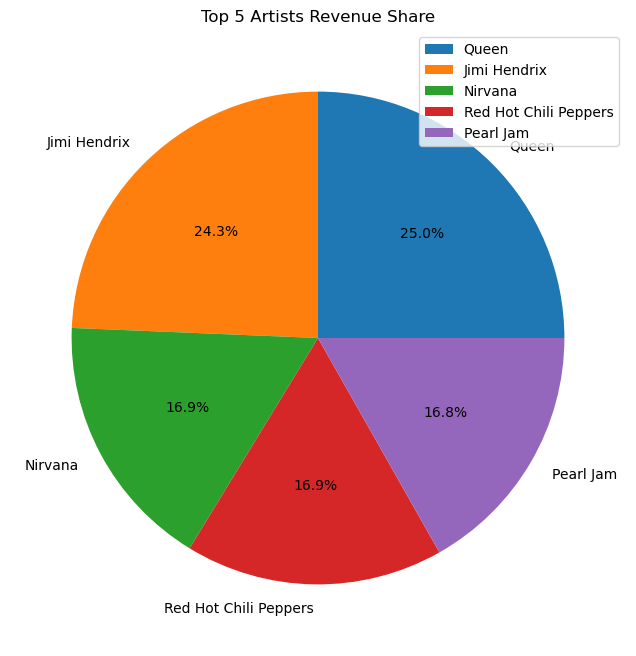

In [20]:
df9.plot(
    kind="pie",
    y="revenue",
    labels=df9["artist"],
    autopct="%1.1f%%",
    figsize=(8,8)
)

plt.title("Top 5 Artists Revenue Share")
plt.ylabel("")
plt.show()

In [21]:
q10 = """
SELECT i.billing_country AS country,

       SUM(
           CASE
               WHEN g.name = 'Rock'
               THEN il.unit_price * il.quantity
               ELSE 0
           END
       ) AS Rock,

       SUM(
           CASE
               WHEN g.name = 'Latin'
               THEN il.unit_price * il.quantity
               ELSE 0
           END
       ) AS Latin,

       SUM(
           CASE
               WHEN g.name = 'Metal'
               THEN il.unit_price * il.quantity
               ELSE 0
           END
       ) AS Metal

FROM invoice i
JOIN invoice_line il
ON i.invoice_id = il.invoice_id

JOIN track t
ON il.track_id = t.track_id

JOIN genre g
ON t.genre_id = g.genre_id

WHERE g.name IN ('Rock', 'Latin', 'Metal')

GROUP BY i.billing_country
ORDER BY i.billing_country
"""

df10 = pd.read_sql_query(q10, conn)
df10

,country,Rock,Latin,Metal
0,Argentina,10.89,1.98,1.98
1,Australia,33.66,1.98,13.86
2,Austria,39.60,0.99,6.93
3,Belgium,25.74,1.98,18.81
4,Brazil,202.95,12.87,72.27
5,Canada,329.67,12.87,71.28
6,Chile,60.39,3.96,10.89
7,Czech Republic,141.57,20.79,22.77
8,Denmark,23.76,0.00,4.95
9,Finland,45.54,1.98,9.90


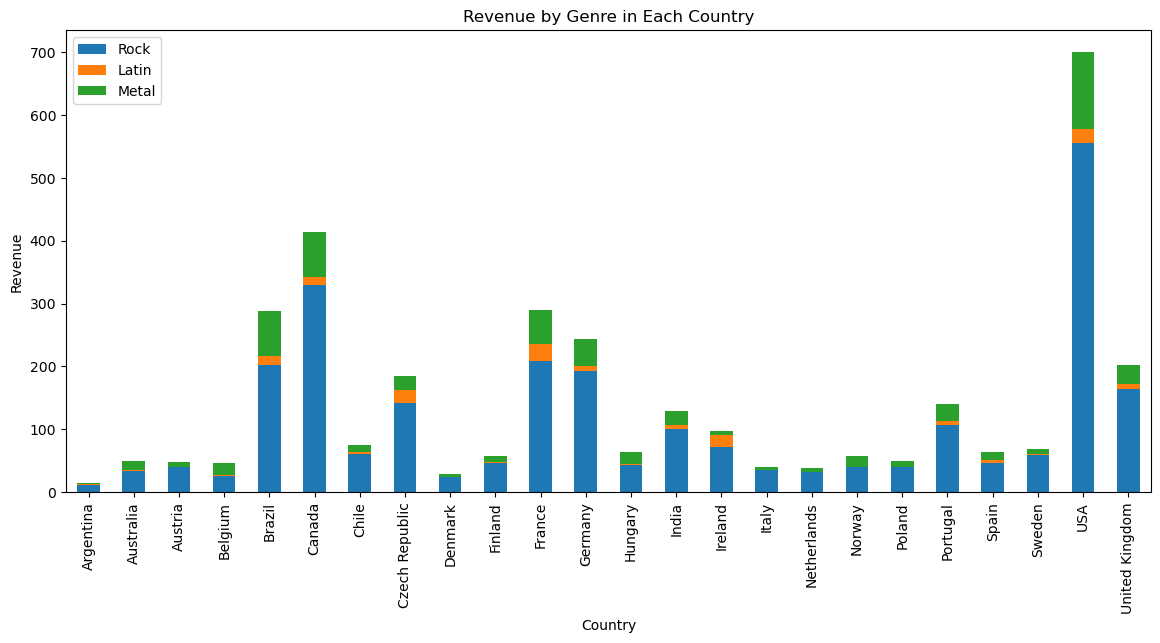

In [22]:
df10.set_index("country")[["Rock", "Latin", "Metal"]].plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)

plt.xlabel("Country")
plt.ylabel("Revenue")
plt.title("Revenue by Genre in Each Country")
plt.xticks(rotation=90)
plt.show()